# Match Initialization

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Cargar el CSV de datos
CSV_PATH = "C:/Users/Maria Fité/Documents/Visca el Barça/more-than-a-hack-2027/data/dataframe_hackaton_final.csv"  # <-- Pon aquí la ruta a tu CSV
df = pd.read_csv(CSV_PATH)

print(f"Dataset cargado: {df.shape[0]} filas y {df.shape[1]} columnas")

# 2. Diccionario de configuración
MATCH_META = {
    "offsets": {1: 1702057, 2: 1702058},
    "halves": {1: (1713242, 1792708), 2: (1812866, 1892255)}
}
VIDEO_FRAMES = 199319

# Frames de las partes
MATCH_META = {"offsets": {1: 1702057, 2: 1702058},
              "halves": {1: (1713242, 1792708), 2: (1812866, 1892255)},
              "kickoffs": {1: {"minute": 7, "second": 27, "frame": 11}, 2: {"minute": 75, "second": 49, "frame": 16}}}
real_halves = {half: (
        (MATCH_META["kickoffs"][half]["minute"] * 60 + MATCH_META["kickoffs"][half]["second"]) * 25 + MATCH_META["kickoffs"][half]["frame"],
        MATCH_META["halves"][half][1] - MATCH_META["offsets"][half])
    for half in [1, 2]}


# 3. Asegurar que 'frame_id' en el df tiene restado el offset (para que coincida con real_halves)
if df["frame_id"].min() > 1000000:
    print("Restando offsets a 'frame_id'...")
    df["frame_id"] = df["frame_id"] - df["period_id"].map(MATCH_META["offsets"])

print("Rangos de frame_id en el CSV por parte:")
print(df.groupby("period_id")["frame_id"].agg(["min", "max", "count"]))
print("Rangos esperados en real_halves:", real_halves)

C:\Users\Maria Fité\AppData\Local\Temp\ipykernel_15580\2633565436.py:7: DtypeWarning: Columns (144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(CSV_PATH)


Dataset cargado: 199319 filas y 265 columnas
Rangos de frame_id en el CSV por parte:
           min     max   count
period_id                     
1            1  199319  199319
Rangos esperados en real_halves: {1: (11186, 90651), 2: (113741, 190197)}


In [40]:
df_filtrado = df[df['set_pieces'].notna() & df['frame_id'].between(85000, 90651)]
display(df_filtrado)

,period_id,timestamp,frame_id,ball_x,ball_y,ball_speed,1_x,1_y,1_s,2_x,...,37_y_vel,38_y_vel,39_y_vel,40_y_vel,41_y_vel,42_y_vel,43_y_vel,44_y_vel,45_y_vel,46_y_vel
84999,1,0 days 00:56:40,85000,0.94849,0.53836,0.002550,0.53071,0.62398,1.006316,NaN,...,NaN,NaN,NaN,NaN,0.00250,NaN,0.00600,NaN,NaN,0.00100
85000,1,0 days 00:56:40.040000,85001,0.94856,0.53821,0.004138,0.53047,0.62454,1.023306,NaN,...,NaN,NaN,NaN,NaN,0.00225,NaN,0.00625,NaN,NaN,0.00200
85001,1,0 days 00:56:40.080000,85002,0.94871,0.53801,0.006250,0.53022,0.62513,1.041425,NaN,...,NaN,NaN,NaN,NaN,0.00225,NaN,0.00675,NaN,NaN,0.00250
85002,1,0 days 00:56:40.120000,85003,0.94893,0.53775,0.008515,0.52998,0.62572,1.060547,NaN,...,NaN,NaN,NaN,NaN,0.00225,NaN,0.00700,NaN,NaN,0.00350
85003,1,0 days 00:56:40.160000,85004,0.94923,0.53743,0.010966,0.52973,0.62633,1.080521,NaN,...,NaN,NaN,NaN,NaN,0.00200,NaN,0.00725,NaN,NaN,0.00475
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86443,1,0 days 00:57:37.760000,86444,0.80952,0.80860,0.027102,NaN,NaN,NaN,NaN,...,NaN,0.07625,NaN,NaN,0.02150,NaN,0.00850,NaN,NaN,0.00250
86444,1,0 days 00:57:37.800000,86445,0.81007,0.80905,0.017766,NaN,NaN,NaN,NaN,...,NaN,0.07525,NaN,NaN,0.02125,NaN,0.00800,NaN,NaN,0.00100
86445,1,0 days 00:57:37.840000,86446,0.81051,0.80915,0.011281,NaN,NaN,NaN,NaN,...,NaN,0.07400,NaN,NaN,0.02125,NaN,0.00725,NaN,NaN,0.00025
86446,1,0 days 00:57:37.880000,86447,0.81085,0.80893,0.010124,NaN,NaN,NaN,NaN,...,NaN,0.07250,NaN,NaN,0.02100,NaN,0.00700,NaN,NaN,0.00125


In [29]:
import numpy as np
import pandas as pd

# ==========================================
# CONFIGURACIÓN DE VARIABLES
# ==========================================

# Variables generales
FPS = 25               # Frames por segundo
VIDEO_FRAMES = 199319  # Frames totales del video
PITCH_CENTER_X = 0.5   # Cambiar a 52.5 si el campo va de 0 a 105
PITCH_CENTER_Y = 0.5   # Cambiar a 34.0 si el campo va de 0 a 68

# Frames de las partes
MATCH_META = {"offsets": {1: 1702057, 2: 1702058},
              "halves": {1: (1713242, 1792708), 2: (1812866, 1892255)},
              "kickoffs": {1: {"minute": 7, "second": 27, "frame": 11}, 2: {"minute": 75, "second": 49, "frame": 16}}}
real_halves = {half: (
        (MATCH_META["kickoffs"][half]["minute"] * 60 + MATCH_META["kickoffs"][half]["second"]) * 25 + MATCH_META["kickoffs"][half]["frame"],
        MATCH_META["halves"][half][1] - MATCH_META["offsets"][half])
    for half in [1, 2]}

# Etiquetas y rangos de jugadores por equipo
HOME_TAG = "H"   # Cambia a "H" o el string exacto que os pidan en el submission
AWAY_TAG = "A"   # Cambia a "A" o el string exacto que os pidan en el submission
HOME_IDS = list(range(1, 25))   # Jugadores del 1 al 24
AWAY_IDS = list(range(25, 47))  # Jugadores del 25 al 46

# Variables threshoold
TH_BALL_SPEED = 0.1




# ==========================================
# PASO 0: PONER LAS 'X' Y SEPARAR PARTES
# ==========================================
def init_frames_with_X(halves_dict=real_halves, n_video_frames=VIDEO_FRAMES):
    """
    Inicializa el DataFrame de predicciones para todo el vídeo.
    Etiqueta con 'X' los tramos fuera de juego (pre-partido, descanso y post-partido)
    y deja en None los frames correspondientes a la 1ª y 2ª parte.

    Args:
        halves_dict (dict): Diccionario {1: (start_1, end_1), 2: (start_2, end_2)} en frames reales.
        n_video_frames (int): Número total de frames del vídeo.

    Returns:
        pd.DataFrame: DataFrame con columnas ['frame', 'label'].
    """

    # 1. Crear el DataFrame con las dos columnas: 'frame' (0 a n_video_frames - 1) y 'label'
    # Inicializamos todo con "X" por defecto
    df_results = pd.DataFrame({
        "frame": range(n_video_frames),
        "label": "X"
    })
    
    # 2. Dejar vacíos (None) los frames que sí corresponden a la 1ª y 2ª parte
    for half, (start_frame, end_frame) in halves_dict.items():
        df_results.loc[start_frame:end_frame, "label"] = None
        
    return df_results




# ==========================================
# PASO 1: FUNCIÓN DE KICK OFF (START)
# ==========================================
def kick_off(df, start_frame, max_wait_frames=500):
    """
    Analiza el saque de centro al inicio de una parte para determinar hacia dónde
    ataca cada equipo, quién empieza con la posesión y en qué frame se pone el balón en juego.

    Args:
        df (pd.DataFrame): DataFrame con los datos de tracking y velocidades.
        start_frame (int): Frame real en el que comienza la parte.
        max_wait_frames (int, optional): Límite de frames a explorar hasta el golpeo inicial.

    Returns:
        tuple:
            - attack_dir (dict): Dirección de ataque por equipo ({'Home': 1/-1, 'Away': -1/1}).
            - starting_team (str): Etiqueta del equipo que realiza el saque ('Home' o 'Away').
            - play_start_frame (int): Frame exacto en el que el balón empieza a moverse.
    """

    # 0. Localizar el frame de inicio en el df
    row_mask = df["frame_id"] == start_frame
    if row_mask.any():
        row = df.loc[row_mask].iloc[0]
    else:
        # Por si falta algún frame exacto, cogemos el primero disponible a partir de start_frame
        row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    # Columnas X de cada equipo
    home_x_cols = [f"{i}_x" for i in HOME_IDS if f"{i}_x" in df.columns]
    away_x_cols = [f"{i}_x" for i in AWAY_IDS if f"{i}_x" in df.columns]


    # 1. Detectar donde ataca cada equipo (Posición jugadores a banda y banda)
    home_median_x = row[home_x_cols].median()
    away_median_x = row[away_x_cols].median()
    # Si la mediana de X es menor, están en el campo izquierdo (X < 0.5) y atacan hacia la derecha (+1)
    if home_median_x < away_median_x:
        attack_dir = {HOME_TAG: 1, AWAY_TAG: -1}
    else:
        attack_dir = {HOME_TAG: -1, AWAY_TAG: 1}

  
    # 2. Definir quien empieza con la posesión (3 jugadores más cercanos a 0.5, 0.5)
    player_distances = []
    for pid in HOME_IDS + AWAY_IDS:
        px = row.get(f"{pid}_x", np.nan)
        py = row.get(f"{pid}_y", np.nan)
        if pd.notna(px) and pd.notna(py):
            dist = np.hypot(px - PITCH_CENTER_X, py - PITCH_CENTER_Y)
            team = HOME_TAG if pid in HOME_IDS else AWAY_TAG
            player_distances.append((dist, team, pid))
    # Ordenar por distancia al centro y coger el más cercano
    player_distances.sort(key=lambda x: x[0])
    starting_team = [item[1] for item in player_distances[:1]]



    # 3. Detectar cuando empieza a jugarse el balón (Cuando la pelota coge velocidad)
    window = df[
        (df["frame_id"] >= start_frame) & 
        (df["frame_id"] <= start_frame + max_wait_frames)
    ]
    dist_ball_center = np.hypot(
        window["ball_x"] - PITCH_CENTER_X, 
        window["ball_y"] - PITCH_CENTER_Y
    )
    # La pelota se juega cuando supera el umbral de velocidad 
    moving_mask = (window["ball_speed"] > TH_BALL_SPEED) 
    moving_frames = window.loc[moving_mask, "frame_id"]

    if not moving_frames.empty:
        play_start_frame = int(moving_frames.iloc[0])
    else:
        play_start_frame = start_frame

    return attack_dir, starting_team, play_start_frame


In [36]:
# 1. Probar Paso 0
df_results = init_frames_with_X(real_halves, VIDEO_FRAMES)
print("Conteo tras Paso 0 (solo X y None):")
print(df_results["label"].value_counts(dropna=False))
print("-" * 50)

# 2. Probar Paso 1 en ambas partes con tu función exacta
for half, (start_frame, end_frame) in real_halves.items():
  attack_dir, starting_team, play_start_frame = kick_off(
      df, start_frame
  )

  # Forzar que sean enteros puros para evitar problemas con .loc
  start_frame = int(start_frame)
  play_start_frame = int(play_start_frame)
  end_frame = int(end_frame)

  # 1. Rellenar con 'D' desde el inicio de la parte hasta el saque
  if play_start_frame > start_frame:
    df_results.loc[start_frame : play_start_frame - 1, "label"] = "D"

  # 2. Rellenar con el equipo que saca el resto de la parte
  df_results.loc[play_start_frame:end_frame, "label"] = str(starting_team)

  print(f"=== PARTE {half} (Inicia en frame {start_frame}) ===")
  print(f"  -> Dirección de ataque : {attack_dir}")

  print(f"  -> Equipo que saca     : {starting_team}")
  print(
      f"  -> Pelota en juego en  : Frame {play_start_frame}"
      f" ({play_start_frame - start_frame} frames en 'D')"
  )
  print()

print("-" * 50)
print("Conteo final en df_results tras Paso 0 y Paso 1:")
print(df_results["label"].value_counts(dropna=False))

Conteo tras Paso 0 (solo X y None):
label
None    155923
X        43396
Name: count, dtype: int64
--------------------------------------------------
=== PARTE 1 (Inicia en frame 11186) ===
  -> Dirección de ataque : {'H': 1, 'A': -1}
  -> Equipo que saca     : ['A']
  -> Pelota en juego en  : Frame 11189 (3 frames en 'D')

=== PARTE 2 (Inicia en frame 113741) ===
  -> Dirección de ataque : {'H': -1, 'A': 1}
  -> Equipo que saca     : ['H']
  -> Pelota en juego en  : Frame 113741 (0 frames en 'D')

--------------------------------------------------
Conteo final en df_results tras Paso 0 y Paso 1:
label
['A']    79463
['H']    76457
X        43396
D            3
Name: count, dtype: int64


In [37]:
print(real_halves)

{1: (11186, 90651), 2: (113741, 190197)}


In [23]:
h1_start = real_halves[1][0]
print("Transición en el inicio de la 1ª Parte:")
display(df_results.loc[h1_start - 3 : h1_start + 15])

h2_start = real_halves[2][0]
print("Transición en el inicio de la 2ª Parte:")
display(df_results.loc[h2_start - 3 : h2_start + 15])

Transición en el inicio de la 1ª Parte:


,frame,label
11183,11183,X
11184,11184,X
11185,11185,X
11186,11186,D
11187,11187,D
11188,11188,D
11189,11189,A
11190,11190,A
11191,11191,A
11192,11192,A


Transición en el inicio de la 2ª Parte:


,frame,label
113738,113738,X
113739,113739,X
113740,113740,X
113741,113741,H
113742,113742,H
113743,113743,H
113744,113744,H
113745,113745,H
113746,113746,H
113747,113747,H


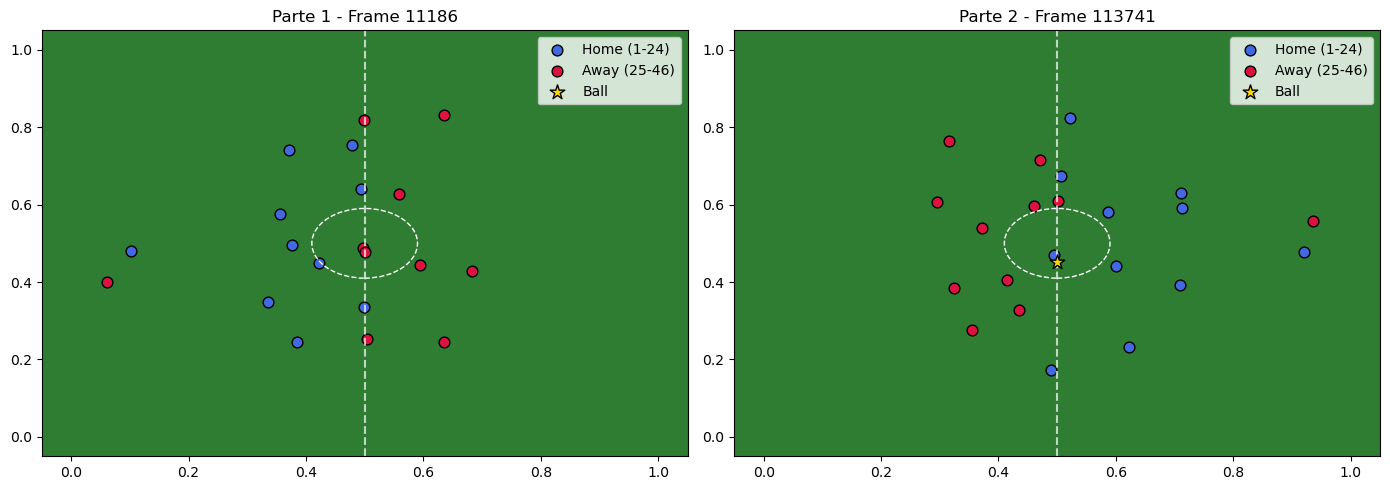

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (half, (start_frame, _)) in enumerate(real_halves.items()):
    ax = axes[idx]
    row = df[df["frame_id"] >= start_frame].iloc[0]
    
    # Pintar jugadores Home (1-24) en Azul
    hx = [row[f"{i}_x"] for i in HOME_IDS if f"{i}_x" in df.columns]
    hy = [row[f"{i}_y"] for i in HOME_IDS if f"{i}_y" in df.columns]
    ax.scatter(hx, hy, c="royalblue", label="Home (1-24)", s=60, edgecolors="black")
    
    # Pintar jugadores Away (25-46) en Rojo
    ax_x = [row[f"{i}_x"] for i in AWAY_IDS if f"{i}_x" in df.columns]
    ax_y = [row[f"{i}_y"] for i in AWAY_IDS if f"{i}_y" in df.columns]
    ax.scatter(ax_x, ax_y, c="crimson", label="Away (25-46)", s=60, edgecolors="black")
    
    # Pintar Pelota
    ax.scatter(row["ball_x"], row["ball_y"], c="gold", label="Ball", s=120, marker="*", edgecolors="black", zorder=5)
    
    # Dibujar líneas del campo [0, 1]
    ax.axvline(0.5, color="white", linestyle="--", alpha=0.7)
    circle = plt.Circle((0.5, 0.5), 0.09, color="white", fill=False, linestyle="--")
    ax.add_patch(circle)
    
    ax.set_facecolor("#2e7d32")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f"Parte {half} - Frame {int(row['frame_id'])}")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [25]:
home_x_cols = [f"{i}_x" for i in HOME_IDS if f"{i}_x" in df.columns]
away_x_cols = [f"{i}_x" for i in AWAY_IDS if f"{i}_x" in df.columns]

for half, (start_frame, _) in real_halves.items():
    row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    
    # Valores de X sin NaNs
    h_vals = row[home_x_cols].dropna()
    a_vals = row[away_x_cols].dropna()
    
    print(f"=== PARTE {half} (Frame {int(row['frame_id'])}) ===")
    print(f"  Home ({len(h_vals)} jug.) -> Mediana X: {h_vals.median():.3f} | Media X: {h_vals.mean():.3f} | Min X (Portero): {h_vals.min():.3f} | Max X: {h_vals.max():.3f}")
    print(f"  Away ({len(a_vals)} jug.) -> Mediana X: {a_vals.median():.3f} | Media X: {a_vals.mean():.3f} | Min X: {a_vals.min():.3f} | Max X (Portero): {a_vals.max():.3f}")
    print()

=== PARTE 1 (Frame 11186) ===
  Home (10 jug.) -> Mediana X: 0.381 | Media X: 0.382 | Min X (Portero): 0.103 | Max X: 0.499
  Away (10 jug.) -> Mediana X: 0.532 | Media X: 0.517 | Min X: 0.061 | Max X (Portero): 0.683

=== PARTE 2 (Frame 113741) ===
  Home (11 jug.) -> Mediana X: 0.600 | Media X: 0.625 | Min X (Portero): 0.490 | Max X: 0.920
  Away (11 jug.) -> Mediana X: 0.415 | Media X: 0.444 | Min X: 0.294 | Max X (Portero): 0.937



In [11]:
for half, (start_frame, _) in real_halves.items():
    row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    
    left_side = []   # Jugadores en X < 0.5
    right_side = []  # Jugadores en X >= 0.5
    
    for i in range(1, 47):
        px = row.get(f"{i}_x", np.nan)
        if pd.notna(px):
            if px < 0.5:
                left_side.append((i, round(px, 3)))
            else:
                right_side.append((i, round(px, 3)))
                
    print(f"=== PARTE {half} (Frame {int(row['frame_id'])}) - Total activos: {len(left_side) + len(right_side)} ===")
    print(f"  Lado Izquierdo (X < 0.5) [{len(left_side)} jug.]: {[x[0] for x in left_side]}")
    print(f"  Lado Derecho   (X >= 0.5) [{len(right_side)} jug.]: {[x[0] for x in right_side]}")
    print()

=== PARTE 1 (Frame 11185) - Total activos: 20 ===
  Lado Izquierdo (X < 0.5) [13 jug.]: [2, 3, 4, 6, 9, 11, 12, 15, 16, 24, 29, 34, 46]
  Lado Derecho   (X >= 0.5) [7 jug.]: [30, 31, 32, 35, 37, 43, 45]

=== PARTE 2 (Frame 110808) - Total activos: 14 ===
  Lado Izquierdo (X < 0.5) [7 jug.]: [9, 13, 14, 15, 17, 18, 20]
  Lado Derecho   (X >= 0.5) [7 jug.]: [4, 21, 24, 35, 38, 41, 46]



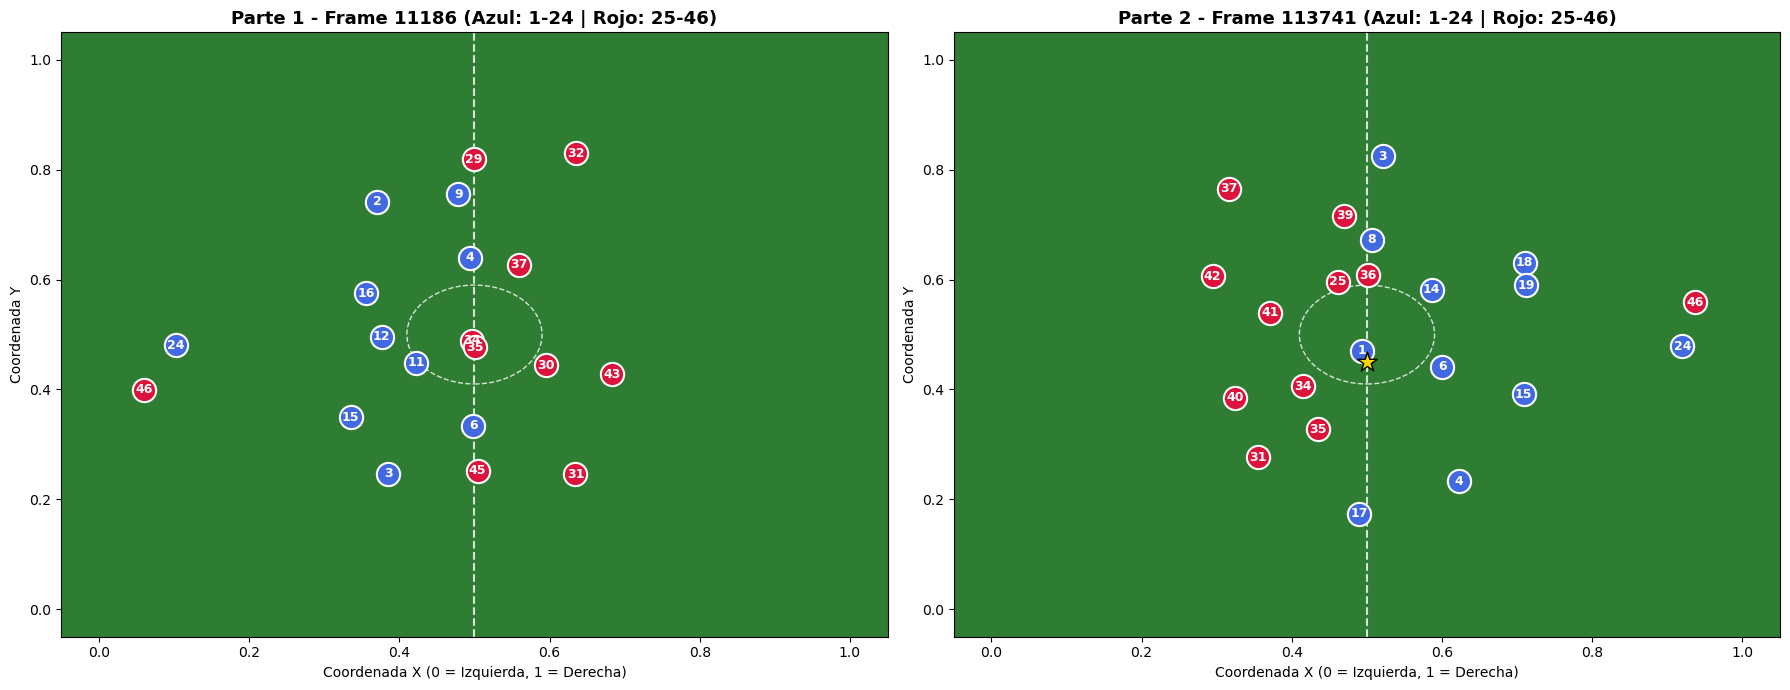

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for idx, (half, (start_frame, _)) in enumerate(real_halves.items()):
    ax = axes[idx]
    row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    
    # Recorrer los 46 posibles jugadores
    for pid in range(1, 47):
        px = row.get(f"{pid}_x", np.nan)
        py = row.get(f"{pid}_y", np.nan)
        
        if pd.notna(px) and pd.notna(py):
            # Color azul para 1-24, rojo para 25-46
            color = "royalblue" if pid <= 24 else "crimson"
            
            # Dibujar el círculo del jugador
            ax.scatter(px, py, c=color, s=280, edgecolors="white", linewidth=1.5, zorder=3)
            
            # Escribir el número del jugador justo encima
            ax.text(
                px, py, str(pid), 
                color="white", fontsize=9, fontweight="bold", 
                ha="center", va="center", zorder=4
            )
            
    # Dibujar la pelota (estrella amarilla)
    if pd.notna(row.get("ball_x")) and pd.notna(row.get("ball_y")):
        ax.scatter(
            row["ball_x"], row["ball_y"], 
            c="gold", s=220, marker="*", edgecolors="black", zorder=5, label="Ball"
        )
    
    # Líneas del campo [0, 1]
    ax.axvline(0.5, color="white", linestyle="--", alpha=0.8)
    circle = plt.Circle((0.5, 0.5), 0.09, color="white", fill=False, linestyle="--", alpha=0.8)
    ax.add_patch(circle)
    
    # Estética del campo
    ax.set_facecolor("#2e7d32")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f"Parte {half} - Frame {int(row['frame_id'])} (Azul: 1-24 | Rojo: 25-46)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Coordenada X (0 = Izquierda, 1 = Derecha)")
    ax.set_ylabel("Coordenada Y")

plt.tight_layout()
plt.show()

Buscando frame real: 121850


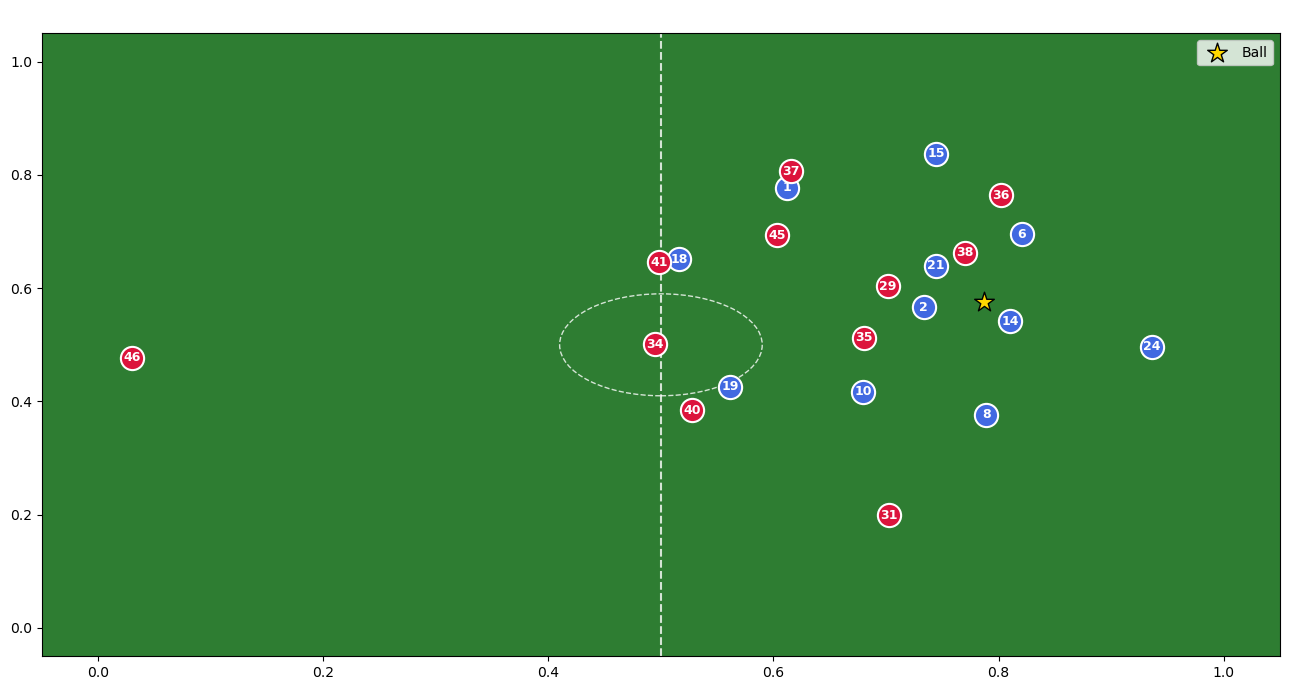

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Calcular el frame real para el minuto 1:21:14 a 25 FPS
hours, minutes, seconds = 1, 21, 14
target_real_frame = (hours * 3600 + minutes * 60 + seconds) * 25

print(f"Buscando frame real: {target_real_frame}")

# 2. Encontrar la fila en el DataFrame (buscando el exacto o el más cercano)
row_match = df[df["frame_id"] == target_real_frame]
if row_match.empty:
  idx_closest = (df["frame_id"] - target_real_frame).abs().idxmin()
  row = df.loc[idx_closest]
  print(
      f"Frame exacto no encontrado. Mostrando el más cercano: ID"
      f" {int(row['frame_id'])}"
  )
else:
  row = row_match.iloc[0]

# 3. Dibujar el campo y los jugadores
fig, ax = plt.subplots(figsize=(13, 7))

HOME_IDS = list(range(1, 25))
AWAY_IDS = list(range(25, 47))

# Pintar jugadores
for pid in range(1, 47):
  px = row.get(f"{pid}_x", np.nan)
  py = row.get(f"{pid}_y", np.nan)

  if pd.notna(px) and pd.notna(py):
    color = "royalblue" if pid <= 24 else "crimson"
    ax.scatter(
        px, py, c=color, s=280, edgecolors="white", linewidth=1.5, zorder=3
    )
    ax.text(
        px,
        py,
        str(pid),
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        zorder=4,
    )

# Pintar la pelota
if pd.notna(row.get("ball_x")) and pd.notna(row.get("ball_y")):
  ax.scatter(
      row["ball_x"],
      row["ball_y"],
      c="gold",
      s=220,
      marker="*",
      edgecolors="black",
      zorder=5,
      label="Ball",
  )

# Geometría básica del campo
ax.axvline(0.5, color="white", linestyle="--", alpha=0.8)
circle = plt.Circle(
    (0.5, 0.5), 0.09, color="white", fill=False, linestyle="--", alpha=0.8
)
ax.add_patch(circle)

ax.set_facecolor("#2e7d32")
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_title(
    f"Minuto 1:21:14 (Frame Real: {int(row['frame_id'])})",
    fontsize=14,
    fontweight="bold",
    color="white",
)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [38]:
# Load Tagging
sys.path.insert(0, os.path.abspath('..'))
print("Cargando Smart Tagging (Eventos)...")
path = games.asset_paths()['smart_tagging']
events_df = sportscode.load(path).to_df()
print(f"-> {len(events_df)} instancias cargadas con éxito.")
display(events_df.head(20))

NameError: name 'sys' is not defined

# Progression

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Cargar el CSV de datos
CSV_PATH = "C:/Users/Maria Fité/Documents/Visca el Barça/more-than-a-hack-2027/data/dataframe_hackaton_final.csv"  # <-- Pon aquí la ruta a tu CSV
df = pd.read_csv(CSV_PATH)


C:\Users\Maria Fité\AppData\Local\Temp\ipykernel_12320\1328775100.py:7: DtypeWarning: Columns (144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(CSV_PATH)


In [42]:
import numpy as np
import pandas as pd

# ==========================================
# CONFIGURACIÓN DE VARIABLES
# ==========================================

# Variables generales
FPS = 25               # Frames por segundo
VIDEO_FRAMES = 199319  # Frames totales del video
PITCH_CENTER_X = 0.5   # Cambiar a 52.5 si el campo va de 0 a 105
PITCH_CENTER_Y = 0.5   # Cambiar a 34.0 si el campo va de 0 a 68
SANITY_WINDOW_FRAMES = 75

# Frames de las partes
MATCH_META = {"offsets": {1: 1702057, 2: 1702058},
              "halves": {1: (1713242, 1792708), 2: (1812866, 1892255)},
              "kickoffs": {1: {"minute": 7, "second": 27, "frame": 11}, 2: {"minute": 75, "second": 49, "frame": 16}}}
real_halves = {half: (
        (MATCH_META["kickoffs"][half]["minute"] * 60 + MATCH_META["kickoffs"][half]["second"]) * 25 + MATCH_META["kickoffs"][half]["frame"],
        MATCH_META["halves"][half][1] - MATCH_META["offsets"][half])
    for half in [1, 2]}

# Etiquetas y rangos de jugadores por equipo
HOME_TAG = "H"   # Cambia a "H" o el string exacto que os pidan en el submission
AWAY_TAG = "A"   # Cambia a "A" o el string exacto que os pidan en el submission
HOME_IDS = list(range(1, 25))   # Jugadores del 1 al 24
AWAY_IDS = list(range(25, 47))  # Jugadores del 25 al 46

# Variables threshoold
TH_BALL_SPEED = 0.1
SANITY_WINDOW_FRAMES = 100  # 3 segundos a 25 FPS
SANITY_RATIO = 0.75        # 75% de la ventana
MARGIN_END_FRAMES = 25*15

# Columnas tácticas del CSV
ATTACK_COLUMNS = [
    "progression", "attacking_trend", "build_up", 
    "long_ball", "creating_chances", "players_in_the_box"
]

DEFENSE_COLUMNS = [
    "defending_in_middle_third", "defensive_transition", 
    "defending_in_attacking_third", "defending_in_defensive_third"
]




# ==========================================
# PASO 0: PONER LAS 'X' Y SEPARAR PARTES
# ==========================================
def init_frames_with_X(halves_dict=real_halves, n_video_frames=VIDEO_FRAMES):
    """
    Inicializa el DataFrame de predicciones para todo el vídeo.
    Etiqueta con 'X' los tramos fuera de juego (pre-partido, descanso y post-partido)
    y deja en None los frames correspondientes a la 1ª y 2ª parte.

    Args:
        halves_dict (dict): Diccionario {1: (start_1, end_1), 2: (start_2, end_2)} en frames reales.
        n_video_frames (int): Número total de frames del vídeo.

    Returns:
        pd.DataFrame: DataFrame con columnas ['frame', 'label'].
    """

    # 1. Crear el DataFrame con las dos columnas: 'frame' (0 a n_video_frames - 1) y 'label'
    # Inicializamos todo con "X" por defecto
    df_results = pd.DataFrame({
        "frame": range(n_video_frames),
        "label": "X"
    })
    
    # 2. Dejar vacíos (None) los frames que sí corresponden a la 1ª y 2ª parte
    for half, (start_frame, end_frame) in halves_dict.items():
        df_results.loc[start_frame:end_frame, "label"] = None
        
    return df_results




# ==========================================
# PASO 1: FUNCIÓN DE KICK OFF (START)
# ==========================================

def kick_off(df, start_frame, max_wait_frames=500):
    """
    Analiza el saque de centro al inicio de una parte para determinar hacia dónde
    ataca cada equipo, quién empieza con la posesión y en qué frame se pone el balón en juego.

    Args:
        df (pd.DataFrame): DataFrame con los datos de tracking y velocidades.
        start_frame (int): Frame real en el que comienza la parte.
        max_wait_frames (int, optional): Límite de frames a explorar hasta el golpeo inicial.

    Returns:
        tuple:
            - attack_dir (dict): Dirección de ataque por equipo ({'H': 1/-1, 'A': -1/1}).
            - starting_team (str): Etiqueta del equipo que realiza el saque ('H' o 'A').
            - play_start_frame (int): Frame exacto en el que el balón empieza a moverse.
    """

    # 0. Localizar el frame de inicio en el df
    row_mask = df["frame_id"] == start_frame
    if row_mask.any():
        row = df.loc[row_mask].iloc[0]
    else:
        # Por si falta algún frame exacto, cogemos el primero disponible a partir de start_frame
        row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    # Columnas X de cada equipo
    home_x_cols = [f"{i}_x" for i in HOME_IDS if f"{i}_x" in df.columns]
    away_x_cols = [f"{i}_x" for i in AWAY_IDS if f"{i}_x" in df.columns]


    # 1. Detectar donde ataca cada equipo (Posición jugadores a banda y banda)
    home_median_x = row[home_x_cols].median()
    away_median_x = row[away_x_cols].median()
    # Si la mediana de X es menor, están en el campo izquierdo (X < 0.5) y atacan hacia la derecha (+1)
    if home_median_x < away_median_x:
        attack_dir = {HOME_TAG: 1, AWAY_TAG: -1}
    else:
        attack_dir = {HOME_TAG: -1, AWAY_TAG: 1}

  
    # 2. Definir quien empieza con la posesión (jugador mas cercano a 0.5, 0.5)
    player_distances = []
    for pid in HOME_IDS + AWAY_IDS:
        px = row.get(f"{pid}_x", np.nan)
        py = row.get(f"{pid}_y", np.nan)
        if pd.notna(px) and pd.notna(py):
            dist = np.hypot(px - PITCH_CENTER_X, py - PITCH_CENTER_Y)
            team = HOME_TAG if pid in HOME_IDS else AWAY_TAG
            player_distances.append((dist, team, pid))
    # Ordenar por distancia al centro y coger el más cercano
    player_distances.sort(key=lambda x: x[0])
    starting_team = [item[1] for item in player_distances[:1]]

    # 3. Detectar cuando empieza a jugarse el balón (Cuando la pelota coge velocidad)
    window = df[
        (df["frame_id"] >= start_frame) & 
        (df["frame_id"] <= start_frame + max_wait_frames)
    ]
    dist_ball_center = np.hypot(
        window["ball_x"] - PITCH_CENTER_X, 
        window["ball_y"] - PITCH_CENTER_Y
    )
    # La pelota se juega cuando supera el umbral de velocidad 
    moving_mask = (window["ball_speed"] > TH_BALL_SPEED) 
    moving_frames = window.loc[moving_mask, "frame_id"]

    if not moving_frames.empty:
        play_start_frame = int(moving_frames.iloc[0])
    else:
        play_start_frame = start_frame

    return attack_dir, starting_team, play_start_frame




# ============================================
# PASO 2: ESTUDIAR Y DEFINIR JUEGO PROGRESIVO
# ============================================


# FUNCIÓN: MAPEA EL EQUIPO CON LAS LABELS

def map_team_str_to_tag(val):
    """
    Traduce el string del dataset a etiqueta corta:
    - Si contiene 'ba'/'Ba' -> 'H'
    - Si contiene 'at'/'At' -> 'A'
    """
    if pd.isna(val):
        return None
    val_str = str(val)
    if "ba" in val_str.lower():
        return HOME_TAG
    elif "at" in val_str.lower():
        return AWAY_TAG
    return None


# FUNCIÓN: CALCULAR JUGADOR MÁS CERCANO POR FRAME

def compute_closest_player_per_frame(df):
    """
    Recorre todas las filas del DataFrame y calcula en cada frame 
    qué equipo tiene al jugador más cercano a la pelota.
    Devuelve la columna 'closest_team' con valores 'H' o 'A'.
    """
    n_rows = len(df)
    ball_x = df["ball_x"].to_numpy()
    ball_y = df["ball_y"].to_numpy()
    
    closest_team_arr = []
    
    # Pre-extraer coordenadas en arrays de numpy para que vaya rapidísimo
    home_x = [df.get(f"{i}_x", pd.Series([np.nan]*n_rows)).to_numpy() for i in range(1, 25)]
    home_y = [df.get(f"{i}_y", pd.Series([np.nan]*n_rows)).to_numpy() for i in range(1, 25)]
    
    away_x = [df.get(f"{i}_x", pd.Series([np.nan]*n_rows)).to_numpy() for i in range(25, 47)]
    away_y = [df.get(f"{i}_y", pd.Series([np.nan]*n_rows)).to_numpy() for i in range(25, 47)]
    
    for idx in range(n_rows):
        bx, by = ball_x[idx], ball_y[idx]
        
        # Si no hay coordenadas válidas de pelota en este frame, dejamos NaN
        if pd.isna(bx) or pd.isna(by):
            closest_team_arr.append(np.nan)
            continue
            
        min_dist = float('inf')
        closest_t = None
        
        # Buscar el jugador más cercano en el equipo Home (1-24)
        for hx_arr, hy_arr in zip(home_x, home_y):
            px, py = hx_arr[idx], hy_arr[idx]
            if not pd.isna(px) and not pd.isna(py):
                d = np.hypot(px - bx, py - by)
                if d < min_dist:
                    min_dist = d
                    closest_t = "H"
                    
        # Buscar el jugador más cercano en el equipo Away (25-46)
        for ax_arr, ay_arr in zip(away_x, away_y):
            px, py = ax_arr[idx], hy_arr[idx] if False else ax_arr[idx] # (seguridad de arrays)
            px, py = ax_arr[idx], ay_arr[idx]
            if not pd.isna(px) and not pd.isna(py):
                d = np.hypot(px - bx, py - by)
                if d < min_dist:
                    min_dist = d
                    closest_t = "A"
                    
        closest_team_arr.append(closest_t)
        
    df["closest_team"] = closest_team_arr
    return df


# FUNCIÓN PRINCIPAL: SANITY CHECK DE 3 NIVELES

def run_final_sanity_check(df, df_results, start_frame, end_frame, initial_team):
    """
    Jerarquía de 3 niveles con conversión robusta a numérico (evita errores de tipo object):
      1. Eventos tácticos del CSV (convirtiendo valores de object a numérico de forma segura).
      2. Jugador más cercano analizando los 75 frames anteriores.
      3. Fallback: Mantener el último equipo con posesión conocida.
    """
    current_team = initial_team
    
    if "closest_team" not in df.columns:
        df = compute_closest_player_per_frame(df)
        
    mask_part = df["frame_id"].between(start_frame, end_frame)
    df_part = df[mask_part].sort_values("frame_id")
    
    frames_list = df_part["frame_id"].to_numpy()
    closest_teams = df_part["closest_team"].to_numpy()
    row_dicts = df_part.to_dict("records")
    
    n = len(frames_list)
    i = 0
    
    while i < n:
        current_frame = int(frames_list[i])
        row_data = row_dicts[i]
        
        ball_is_valid = pd.notna(row_data.get("ball_x")) and pd.notna(row_data.get("ball_y"))
        
        # ---------------------------------------------------------
        # NIVEL 1: Eventos tácticos (con conversión segura a numérico)
        # ---------------------------------------------------------
        tactical_forced_team = None
        
        # Comprobar ataques
        for col in ATTACK_COLUMNS:
            val_raw = row_data.get(col, 0)
            # Convertir de object/string a numérico de forma segura
            val = pd.to_numeric(val_raw, errors='coerce')
            if pd.isna(val):
                val = 0
                
            # Regla especial para players_in_the_box: ignorar si es 1 o 2 (debe ser > 2)
            if col == "players_in_the_box":
                is_active = (val > 2)
            else:
                is_active = (val == 1)
                
            if is_active:
                # Look-ahead contando frames mientras siga activo
                remaining_frames = 0
                k = i
                while k < n:
                    k_val_raw = row_dicts[k].get(col, 0)
                    k_val = pd.to_numeric(k_val_raw, errors='coerce')
                    if pd.isna(k_val):
                        k_val = 0
                        
                    if col == "players_in_the_box":
                        if k_val <= 2:
                            break
                    else:
                        if k_val != 1:
                            break
                    remaining_frames += 1
                    k += 1
                
                # Si estamos a más de 15 segundos (375 frames) del final del evento, lo obedecemos
                if remaining_frames > MARGIN_END_FRAMES:
                    team_col = f"{col}_team"
                    if team_col in row_data:
                        mapped = map_team_str_to_tag(row_data[team_col])
                        if mapped is not None:
                            tactical_forced_team = mapped
                            break
                    
        # Comprobar defensas
        if tactical_forced_team is None:
            for col in DEFENSE_COLUMNS:
                val_raw = row_data.get(col, 0)
                val = pd.to_numeric(val_raw, errors='coerce')
                if pd.isna(val):
                    val = 0
                    
                if val == 1:
                    remaining_frames = 0
                    k = i
                    while k < n:
                        k_val_raw = row_dicts[k].get(col, 0)
                        k_val = pd.to_numeric(k_val_raw, errors='coerce')
                        if pd.isna(k_val):
                            k_val = 0
                        if k_val != 1:
                            break
                        remaining_frames += 1
                        k += 1
                    
                    if remaining_frames > MARGIN_END_FRAMES:
                        team_col = f"{col}_team"
                        if team_col in row_data:
                            def_tag = map_team_str_to_tag(row_data[team_col])
                            if def_tag is not None:
                                tactical_forced_team = AWAY_TAG if def_tag == HOME_TAG else HOME_TAG
                                break
                        
        if tactical_forced_team is not None:
            current_team = tactical_forced_team
            
        else:
            # ---------------------------------------------------------
            # NIVEL 2: Ventana de los 75 frames ANTERIORES (Geometría)
            # ---------------------------------------------------------
            if ball_is_valid and i >= SANITY_WINDOW_FRAMES:
                window_teams = closest_teams[i - SANITY_WINDOW_FRAMES : i]
                window_teams_clean = window_teams[pd.notna(window_teams)]
                
                if len(window_teams_clean) > 0:
                    rival_team = AWAY_TAG if current_team == HOME_TAG else HOME_TAG
                    rival_ratio = np.mean(window_teams_clean == rival_team)
                    
                    if rival_ratio >= SANITY_RATIO:
                        current_team = rival_team
                        
            # ---------------------------------------------------------
            # NIVEL 3: Fallback (Mantiene el `current_team` anterior)
            # ---------------------------------------------------------
            pass
        
        # Asignar la posesión resuelta al frame actual
        df_results.loc[current_frame, "label"] = current_team
        i += 1
        
    return df_results

In [43]:
# ==========================================
# TEST: PRIMEROS 10 MINUTOS DE LA 1ª PARTE
# ==========================================

# 1. Definir los límites de la prueba
start_frame_p1 = int(real_halves[1][0]) # Frame de inicio oficial (kickoff)
FPS = 25
ten_minutes_frames = 10 * 60 * FPS       # 10 minutos * 60 segundos * 25 FPS = 15,000 frames
end_frame_test = start_frame_p1 + ten_minutes_frames

print(f"--- INICIANDO TEST (1ª Parte: 10 primeros minutos) ---")
print(f"Frame de inicio (Kick-off): {start_frame_p1}")
print(f"Frame de fin del test     : {end_frame_test}")

# 2. Inicializar un DataFrame de resultados limpio solo para esta prueba)
df_results = init_frames_with_X(real_halves, VIDEO_FRAMES)
print("Conteo tras Paso 0 (solo X y None):")
print(df_results["label"].value_counts(dropna=False))
print("-" * 50)

# 3. Obtener los datos de inicio del kick-off para la Parte 1
attack_dir, starting_team, play_start_frame = kick_off(df, start_frame_p1)
play_start_frame = int(play_start_frame)

print(f"Equipo que saca en el kickoff: {starting_team}")
print(f"Pelota en juego oficial en el frame: {play_start_frame}")

# 4. Rellenar con 'D' (Dead Ball) el tramo previo al saque si lo hubiera
if play_start_frame > start_frame_p1:
    df_results.loc[start_frame_p1 : play_start_frame - 1, "label"] = "D"

# 5. Asegurarnos de que el cálculo del jugador más cercano está hecho
if "closest_team" not in df.columns:
    print("Calculando jugador más cercano para todo el dataset...")
    df = compute_closest_player_per_frame(df)

# 6. Ejecutar la función de sanity check limitada a estos 10 minutos
print("Ejecutando 'run_final_sanity_check' para el test...")
df_results = run_final_sanity_check(
    df=df,
    df_results=df_results,
    start_frame=play_start_frame,
    end_frame=end_frame_test,
    initial_team=starting_team
)

# 7. Mostrar resultados y estadísticas del test
print("\n--- RESULTADOS DEL TEST (10 primeros min) ---")
mask_test = df["frame_id"].between(start_frame_p1, end_frame_test)
conteo_etiquetas = df_results.loc[df[mask_test].index, "label"].value_counts()
print(conteo_etiquetas)

--- INICIANDO TEST (1ª Parte: 10 primeros minutos) ---
Frame de inicio (Kick-off): 11186
Frame de fin del test     : 26186
Conteo tras Paso 0 (solo X y None):
label
None    155923
X        43396
Name: count, dtype: int64
--------------------------------------------------
Equipo que saca en el kickoff: ['A']
Pelota en juego oficial en el frame: 11189
Ejecutando 'run_final_sanity_check' para el test...

--- RESULTADOS DEL TEST (10 primeros min) ---
label
H      9901
A      5081
[A]      15
D         3
X         1
Name: count, dtype: int64


In [44]:
# 8. SEGUIMIENTO DETALLADO CADA SEGUNDO (25 frames) con TIPO DE EVENTO
print("\n--- SEGUIMIENTO DETALLADO DE POSESIÓN Y EVENTOS (CADA SEGUNDO) ---")
print(f"{'FRAME':<10} | {'TIEMPO':<10} | {'POSESIÓN':<10} | {'BALÓN OK':<10} | {'TIPO DE EVENTO':<25} | {'ATAQUE EQUIPO':<15} | {'DEFENSA EQUIPO':<15}")
print("-" * 102)

# Recorrer el rango de los 10 minutos saltando de 25 en 25 frames
for f_id in range(start_frame_p1, end_frame_test + 1, 25):
    # Buscar la fila correspondiente en el dataframe principal usando el frame_id
    row_match = df[df["frame_id"] == f_id]
    
    if not row_match.empty:
        idx = row_match.index[0]
        row_data = row_match.iloc[0]
        
        # 1. Posesión asignada
        possession = df_results.loc[idx, "label"] if idx in df_results.index else "-"
        
        # 2. Calcular tiempo en formato Minutos:Segundos desde el inicio del test
        frames_elapsed = f_id
        total_seconds = frames_elapsed / FPS
        minutes = int(total_seconds // 60)
        seconds = int(total_seconds % 60)
        time_str = f"{minutes:02d}:{seconds:02d}"
        
        # 3. Comprobar si hay posición de balón válida
        has_ball = "Sí" if (pd.notna(row_data.get("ball_x")) and pd.notna(row_data.get("ball_y"))) else "No"
        
        # 4. Detectar el tipo de evento activo y qué equipo interviene
        active_event_type = "-"
        active_attack_team = "-"
        active_defense_team = "-"
        
        # Buscar en columnas de ataque
        for col in ATTACK_COLUMNS:
            if col in row_data and row_data[col] == 1:
                active_event_type = col
                team_col = f"{col}_team"
                if team_col in row_data:
                    active_attack_team = str(row_data[team_col])
                break
                
        # Si no hay ataque, buscar en columnas de defensa
        if active_event_type == "-":
            for col in DEFENSE_COLUMNS:
                if col in row_data and row_data[col] == 1:
                    active_event_type = col
                    team_col = f"{col}_team"
                    if team_col in row_data:
                        active_defense_team = str(row_data[team_col])
                    break
        
        print(f"{f_id:<10} | {time_str:<10} | {possession:<10} | {has_ball:<10} | {active_event_type:<25} | {active_attack_team:<15} | {active_defense_team:<15}")


--- SEGUIMIENTO DETALLADO DE POSESIÓN Y EVENTOS (CADA SEGUNDO) ---
FRAME      | TIEMPO     | POSESIÓN   | BALÓN OK   | TIPO DE EVENTO            | ATAQUE EQUIPO   | DEFENSA EQUIPO 
------------------------------------------------------------------------------------------------------
11186      | 07:27      | X          | No         | long_ball                 | Atletic Club    | -              
11211      | 07:28      | A          | Sí         | progression               | Atletic Club    | -              
11236      | 07:29      | A          | Sí         | progression               | Atletic Club    | -              
11261      | 07:30      | A          | Sí         | progression               | Atletic Club    | -              
11286      | 07:31      | A          | Sí         | progression               | Atletic Club    | -              
11311      | 07:32      | A          | Sí         | progression               | Atletic Club    | -              
11336      | 07:33      | A    

# Set Pieces

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Cargar el CSV de datos
CSV_PATH = "C:/Users/Maria Fité/Documents/Visca el Barça/more-than-a-hack-2027/data/dataframe_hackaton_final.csv"  # <-- Pon aquí la ruta a tu CSV
df = pd.read_csv(CSV_PATH)

C:\Users\Maria Fité\AppData\Local\Temp\ipykernel_15800\4215479847.py:7: DtypeWarning: Columns (144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(CSV_PATH)


In [30]:
import numpy as np
import pandas as pd

# ==========================================
# CONFIGURACIÓN DE LÍMITES (NORMALIZADO 0 - 1)
# ==========================================
X_MIN, X_MAX = 0.00, 0.1  # Umbrales para considerar que sale por la línea de fondo
Y_MIN, Y_MAX = 0.00, 0.1 # Umbrales para considerar que sale por el lateral
LOOKBACK_FRAMES = 250      # 10 segundos a 25 FPS


# ==================================================
# SACAR LOS BOLEANOS MIRANDO LOS 250 FRAMES PREVIOS
# ==================================================

def extract_set_piece_booleans(df_part, current_idx):
    """
    Analiza los últimos 250 frames hasta el índice actual (current_idx) 
    adaptado a coordenadas normalizadas de 0 a 1.
    """
    start_win = max(0, current_idx - LOOKBACK_FRAMES)
    window_df = df_part.iloc[start_win : current_idx + 1]
    current_row = df_part.iloc[current_idx]
    
    # 1. PILOTA SURT PEL LATERAL (Y fuera de [0, 1])
    ball_out_lateral = False
    for _, row in window_df.iterrows():
        by = row.get("ball_y", np.nan)
        if pd.notna(by) and (by < 0.0 or by > 1.0):
            ball_out_lateral = True
            break

    # 2. PILOTA SURT PEL FONS (X fuera de [0, 1])
    ball_out_fondo = False
    for _, row in window_df.iterrows():
        bx = row.get("ball_x", np.nan)
        if pd.notna(bx) and (bx < 0.0 or bx > 1.0):
            ball_out_fondo = True
            break

    # 3. AGLOMERACIÓN CÓRNER (Jugadores en las 4 esquinas del campo 0-1)
    corner_frames_count = 0
    for _, row in window_df.iterrows():
        c_home, c_away = 0, 0
        for i in range(1, 25): # Home
            px, py = row.get(f"{i}_x", np.nan), row.get(f"{i}_y", np.nan)
            if pd.notna(px) and pd.notna(py) and (px < 0.1 or px > 0.9) and (py < 0.1 or py > 0.9):
                c_home += 1
        for i in range(25, 47): # Away
            px, py = row.get(f"{i}_x", np.nan), row.get(f"{i}_y", np.nan)
            if pd.notna(px) and pd.notna(py) and (px < 0.1 or px > 0.9) and (py < 0.1 or py > 0.9):
                c_away += 1
        if c_home >= 5 or c_away >= 5:
            corner_frames_count += 1
            
    aglomeracion_corner = (corner_frames_count >= 25)

    # 4. AGLOMERACIÓN MIG (Centro del campo: X entre 0.4 y 0.6)
    mig_frames_count = 0
    for _, row in window_df.iterrows():
        midfield_low_speed_count = 0
        for i in range(1, 47):
            px = row.get(f"{i}_x", np.nan)
            vx = row.get(f"{i}_x_vel", 0)
            vy = row.get(f"{i}_y_vel", 0)
            if pd.notna(px) and (0.4 <= px <= 0.6):
                speed = np.hypot(vx, vy) if pd.notna(vx) and pd.notna(vy) else 99
                if speed < 0.01:
                    midfield_low_speed_count += 1
        if midfield_low_speed_count >= 10:
            mig_frames_count += 1
            
    aglomeracion_mig = (mig_frames_count >= 25)

    # 5. JUGADOR AL FONDO
    lateral_frames_count = 0
    for _, row in window_df.iterrows():
        lateral_low_speed_count = 0
        for i in range(1, 47):
            px = row.get(f"{i}_x", np.nan)
            py = row.get(f"{i}_y", np.nan)
            vx = row.get(f"{i}_x_vel", 0)
            vy = row.get(f"{i}_y_vel", 0)
            if pd.notna(px) and pd.notna(py):
                speed = np.hypot(vx, vy) if pd.notna(vx) and pd.notna(vy) else 99
                if speed < 0.01 and (py <= 0.08 or py >= 0.92):
                    lateral_low_speed_count += 1
        if lateral_low_speed_count >= 7:
            lateral_frames_count += 1
    jugador_al_lateral = (lateral_frames_count >= 25)

    # 6. JUGADOR PARAT EN SEC (Velocidad casi 0 en escala 0-1)
    jugador_parat_en_sec = False
    
    # Umbrales de velocidad baja en escala normalizada (0 - 1)
    BALL_LOW_SPEED_THRESHOLD = 0.008
    PLAYER_LOW_SPEED_THRESHOLD = 0.015
    MIN_CONSECUTIVE_FRAMES = 50  # 2 segundos a 25 FPS
    
    consecutive_stopped_count = 0
    max_consecutive_stopped = 0
    
    for _, row in window_df.iterrows():
        bx = row.get("ball_x", np.nan)
        by = row.get("ball_y", np.nan)
        
        # 1. Obtener velocidad de la pelota
        b_speed = row.get("ball_speed", np.nan)
        if pd.isna(b_speed):
            bx_vel = row.get("ball_x_vel", 0)
            by_vel = row.get("ball_y_vel", 0)
            b_speed = np.hypot(bx_vel, by_vel) if pd.notna(bx_vel) and pd.notna(by_vel) else 99
            
        # 2. Encontrar el jugador más cercano a la pelota en este frame de la ventana
        closest_player_speed = 99
        if pd.notna(bx) and pd.notna(by):
            min_dist = float('inf')
            closest_idx = None
            
            for i in range(1, 47):
                px = row.get(f"{i}_x", np.nan)
                py = row.get(f"{i}_y", np.nan)
                if pd.notna(px) and pd.notna(py):
                    dist = np.hypot(px - bx, py - by)
                    if dist < min_dist:
                        min_dist = dist
                        closest_idx = i
                        
            # Si encontramos al jugador más cercano, calculamos su velocidad
            if closest_idx is not None:
                pvx = row.get(f"{closest_idx}_x_vel", 0)
                pvy = row.get(f"{closest_idx}_y_vel", 0)
                closest_player_speed = np.hypot(pvx, pvy) if pd.notna(pvx) and pd.notna(pvy) else 99
                
        # 3. Comprobar si ambos están parados en este frame
        if b_speed < BALL_LOW_SPEED_THRESHOLD and closest_player_speed < PLAYER_LOW_SPEED_THRESHOLD:
            consecutive_stopped_count += 1
        else:
            consecutive_stopped_count = 0  # Se rompe la racha si alguno acelera
            
        if consecutive_stopped_count > max_consecutive_stopped:
            max_consecutive_stopped = consecutive_stopped_count

    # Si la racha de parón conjunto ha durado más de 50 frames (2 segundos)
    if max_consecutive_stopped >= MIN_CONSECUTIVE_FRAMES:
        jugador_parat_en_sec = True

    # 7. Estimación por NaNs en la ventana (recorriendo cada frame)
    estimated_out_x = False
    estimated_out_y = False
    ball_loose = False
    
    # Iterar por la ventana buscando dónde aparecen los NaNs
    for idx_w in range(len(window_df)):
        row_w = window_df.iloc[idx_w]
        bx_w = row_w.get("ball_x", np.nan)
        by_w = row_w.get("ball_y", np.nan)
        
        # Si encontramos un NaN en la pelota dentro de la ventana
        if pd.isna(bx_w) or pd.isna(by_w):
            ball_loose = True  
            # Mirar el frame inmediatamente anterior dentro de la ventana para coger la última posición y velocidad válidas
            if idx_w > 0:
                prev_row = window_df.iloc[idx_w - 1]
                last_x = prev_row.get("ball_x", np.nan)
                last_y = prev_row.get("ball_y", np.nan)
                vx = prev_row.get("ball_x_vel", 0)
                vy = prev_row.get("ball_y_vel", 0)
                
                if pd.notna(last_x) and pd.notna(last_y):
                    # Proyectar asumiendo 1 frame de salto (1/25 segundos) o usando las velocidades
                    # Si estaba cerca de los bordes y la velocidad lo sacaba:
                    if last_x < 0.15 or last_x > 0.85:
                        if pd.notna(vx) and vx != 0:
                            pred_x = last_x + (vx * (1.0 / 25.0))
                            if pred_x <= 0.0 or pred_x >= 1.0:
                                estimated_out_x = True
                                break
                                
                    if last_y < 0.15 or last_y > 0.85:
                        if pd.notna(vy) and vy != 0:
                            pred_y = last_y + (vy * (1.0 / 25.0))
                            if pred_y <= 0.0 or pred_y >= 1.0:
                                estimated_out_y = True
                                break


    return {
        "ball_out_lateral": ball_out_lateral,
        "ball_out_fondo": ball_out_fondo,
        "aglomeracion_corner": aglomeracion_corner,
        "aglomeracion_mig": aglomeracion_mig,
        "jugador_al_lateral": jugador_al_lateral,
        "jugador_parat_en_sec": jugador_parat_en_sec,
        "estimated_out_x": estimated_out_x,
        "estimated_out_y": estimated_out_y,
        "ball_loose": ball_loose}




# ==================================================
# DETERMINAR EL SET PICE
# ==================================================

def classify_set_piece_event(booleans_dict):
    """
    Determina el tipo de set piece basándose en el diccionario completo de booleanos,
    incluyendo la detección de Free Kick.
    """
    ball_out_lat = booleans_dict.get("ball_out_lateral", False)
    est_out_y = booleans_dict.get("estimated_out_y", False)
    ball_out_fon = booleans_dict.get("ball_out_fondo", False)
    est_out_x = booleans_dict.get("estimated_out_x", False)
    aglom_corner = booleans_dict.get("aglomeracion_corner", False)
    aglom_mig = booleans_dict.get("aglomeracion_mig", False)
    jugador_lat = booleans_dict.get("jugador_al_lateral", False)
    jugador_parado = booleans_dict.get("jugador_parat_en_sec", False)
    ball_loose = booleans_dict.get("ball_loose", False)
    
    # 1. THROW IN (Saque de banda)
    if ball_out_lat or (est_out_y and ball_loose):
        return "Throw In"
        
    # 2. CORNER / GOAL KICK (Saque de esquina o de puerta)
    if ball_out_fon or (est_out_x and ball_loose) and not aglom_corner:
        return "Corner / Goal Kick"
        
    # 3. KICK OFF AFTER GOAL (Saque de centro tras gol)
    if aglom_corner and (est_out_x and ball_loose):
        return "Kick Off After Goal"
        
    # 4. FREE KICK (Falta)
    if jugador_parado and not aglom_mig:
        return "Free Kick"
        
    # 5. PARADA DE JUEGO / BALÓN SUELTO (Interrupción general)
    if jugador_lat or aglom_mig:
        return "Parada de Juego"
        
    # 6. OPEN PLAY (Juego en curso por defecto)
    return None




# ==================================================
# TROBAR INICI EVENT
# ==================================================

def find_event_onset_frame(df_part, current_idx, event_type):
    """
    Busca hacia atrás dentro de la ventana de los 250 frames el frame exacto 
    donde se originó el evento basándose en su disparatador físico.
    """
    start_win = max(0, current_idx - 500)
    window_df = df_part.iloc[start_win : current_idx + 1]
    onset_idx = current_idx  # Por defecto el actual si no se halla el flanco exacto
    
    # 1. EVENTOS DE SALIDA DEL CAMPO (Throw In, Corner, Goal Kick, Kick Off)
    if event_type in ["Throw In", "Corner / Goal Kick", "Kick Off After Goal"]:
        # Buscamos el primer frame de la ventana donde la pelota cruza físicamente los límites
        for idx, row in window_df.iterrows():
            bx = row.get("ball_x", np.nan)
            by = row.get("ball_y", np.nan)
            
            # Si sale por bandas (Y) o fondos (X)
            if (pd.notna(bx) and (bx < 0.0 or bx > 1.0)) or (pd.notna(by) and (by < 0.0 or by > 1.0)):
                onset_idx = df_part.index.get_loc(idx)
                break
                
        # Si no salió físicamente por culpa de un NaN, buscamos dónde empezó la pérdida de señal / estimación
        if onset_idx == current_idx:
            for idx, row in window_df.iterrows():
                if pd.isna(row.get("ball_x")) or pd.isna(row.get("ball_y")):
                    onset_idx = df_part.index.get_loc(idx)
                    break

    # 2. FREE KICK (Falta) -> El jugador más cercano se para en seco
    elif event_type == "Free Kick":
        # Buscamos el inicio de la racha de frenazo del jugador más cercano al balón
        consecutive_stops = 0
        for idx, row in window_df.iterrows():
            bx, by = row.get("ball_x", np.nan), row.get("ball_y", np.nan)
            if pd.notna(bx) and pd.notna(by):
                # Encontrar distancia mínima al jugador
                min_dist = float('inf')
                c_idx = None
                for i in range(1, 47):
                    px, py = row.get(f"{i}_x", np.nan), row.get(f"{i}_y", np.nan)
                    if pd.notna(px) and pd.notna(py):
                        dist = np.hypot(px - bx, py - by)
                        if dist < min_dist:
                            min_dist = dist
                            c_idx = i
                            
                if c_idx is not None:
                    pvx = row.get(f"{c_idx}_x_vel", 0)
                    pvy = row.get(f"{c_idx}_y_vel", 0)
                    pspeed = np.hypot(pvx, pvy) if pd.notna(pvx) and pd.notna(pvy) else 99
                    
                    # Si el jugador baja drásticamente la velocidad (< 0.015)
                    if pspeed < 0.015:
                        consecutive_stops += 1
                        if consecutive_stops == 1: # ¡Primer frame del frenazo!
                            onset_idx = df_part.index.get_loc(idx)
                    else:
                        consecutive_stops = 0

    # 3. PARADA DE JUEGO -> Descenso general de velocidades
    elif event_type == "Parada de Juego":
        for idx, row in window_df.iterrows():
            b_speed = row.get("ball_speed", np.nan)
            if pd.isna(b_speed):
                bx_v = row.get("ball_x_vel", 0)
                by_v = row.get("ball_y_vel", 0)
                b_speed = np.hypot(bx_v, by_v) if pd.notna(bx_v) and pd.notna(by_v) else 99
                
            # Frame exacto donde la velocidad del balón cae por debajo del umbral de parón
            if b_speed < 0.008:
                onset_idx = df_part.index.get_loc(idx)
                break

    return onset_idx




# ==================================================
# TROBAR FINAL I POSSESSIÓ 
# ==================================================
def find_event_end_and_executor(df_part, current_idx, current_team):
    """
    Busca hacia adelante desde el índice actual el momento en que el balón 
    se pone en movimiento (fin del evento) e identifica qué jugador de qué equipo lo ejecuta.
    """
    # Miramos hacia adelante (ej. los siguientes 150 frames / 6 segundos)
    end_win = min(len(df_part) + 24, current_idx + 500)
    future_df = df_part.iloc[current_idx : end_win + 1]
    
    end_frame_id = None
    executor_player_id = None
    executor_team = None
    
    BALL_ACCEL_THRESHOLD = 0.1  # Umbral de velocidad para considerar que el balón ha salido disparado
    
    for idx, row in future_df.iterrows():
        bx = row.get("ball_x", np.nan)
        by = row.get("ball_y", np.nan)
        
        # 1. Obtener la velocidad del balón en este frame futuro
        b_speed = row.get("ball_speed", np.nan)
        if pd.isna(b_speed):
            bx_v = row.get("ball_x_vel", 0)
            by_v = row.get("ball_y_vel", 0)
            b_speed = np.hypot(bx_v, by_v) if pd.notna(bx_v) and pd.notna(by_v) else 0
            
        # 2. Comprobar si el balón se ha puesto en movimiento (supera el umbral de aceleración)
        if b_speed > BALL_ACCEL_THRESHOLD and pd.notna(bx) and pd.notna(by):
            end_frame_id = row.get("frame_id", idx)
            
            # 3. Identificar quién pone el balón en movimiento (el jugador más cercano que se está moviendo)
            min_dist = float('inf')
            best_player = None
            
            for i in range(1, 47):
                px = row.get(f"{i}_x", np.nan)
                py = row.get(f"{i}_y", np.nan)
                if pd.notna(px) and pd.notna(py):
                    dist = np.hypot(px - bx, py - by)
                    if dist < min_dist:
                        min_dist = dist
                        best_player = i
                        
            if best_player is not None:
                executor_player_id = best_player
                # Asignar equipo según el ID del jugador (Home: 1-24, Away: 25-46)
                executor_team = "H" if executor_player_id <= 24 else "A"
                
            break # Encontramos el momento exacto del saque y rompemos el bucle
            
    # Fallback si no acelera claramente en la ventana futura
    if end_frame_id is None and len(future_df) > 0:
        end_frame_id = future_df.iloc[-1].get("frame_id", df_part.iloc[current_idx]["frame_id"])
        
    return {
        "end_frame": end_frame_id,
        "executor_player": executor_player_id,
        "executor_team": executor_team
    }


In [23]:
import pandas as pd
import numpy as np

def run_pipeline_test(df, start_frame, end_frame, initial_team="Home"):
    """
    Ejecuta el pipeline de set pieces SOLO en el primer frame de detección 
    según la columna de entrada (ajustada a 'set_pice' o 'set_pieces').
    """
    print(f"--- INICIANDO TEST DEL PIPELINE (Frames {start_frame} a {end_frame}) ---")
    
    df_results = df.copy()
    if "label" not in df_results.columns:
        df_results["label"] = np.nan
        
    # Filtrar la parte del DataFrame a procesar
    mask_part = df_results["frame_id"].between(start_frame, end_frame)
    df_part = df_results[mask_part].sort_values("frame_id").reset_index(drop=True)
    
    events_detected = []
    
    # Variable de control para saber si ya estamos dentro de un set piece
    in_set_piece = False
    
    for current_idx in range(len(df_part)):
        current_row = df_part.iloc[current_idx]
        current_frame_id = current_row["frame_id"]
        
        # 1. Obtener el valor de la columna de entrada de set pieces 
        # (Asegúrate de que el nombre coincida con tu DataFrame: 'set_pice' o 'set_pieces')
        input_set_piece = current_row.get("set_pice", current_row.get("set_pieces", 0))
        
        # Comprobar si es un valor válido de set piece (que no sea NaN, 0 ni "Open Play")
        is_valid_event = pd.notna(input_set_piece) and input_set_piece != 0 and input_set_piece != "Open Play"
        
        # 2. DETECCIÓN DEL PRIMER FRAME (TRANSICIÓN)
        # El evento comienza si es un evento válido y ANTES no estábamos en un set piece
        if is_valid_event and not in_set_piece:
            in_set_piece = True # Marcamos que entramos en un set piece
            
            # A. Extraer booleans y clasificar (tu lógica de algoritmo)
            booleans = extract_set_piece_booleans(df_part, current_idx)
            predicated_event = classify_set_piece_event(booleans)
            
            # B. Fallback si el clasificador devuelve None
            if predicated_event is not None:
                final_event = predicated_event
            else:
                final_event = input_set_piece
                
            # C. Analizar inicio (onset) y fin (offset) del evento
            onset_idx = find_event_onset_frame(df_part, current_idx, final_event)
            start_f_id = df_part.iloc[onset_idx]["frame_id"]
            
            end_info = find_event_end_and_executor(df_part, current_idx, initial_team)
            
            event_record = {
                "frame_deteccion": current_frame_id,
                "evento": final_event,
                "frame_inicio": start_f_id,
                "frame_fin": end_info["end_frame"],
                "ejecutor_jugador": end_info["executor_player"],
                "ejecutor_equipo": end_info["executor_team"]
            }
            
            events_detected.append(event_record)
            
            # Imprimir por pantalla únicamente cuando detecta el inicio
            print(f"[INICIO SET PIECE] {final_event} | Frame Det.: {current_frame_id} | Inicio Real: {start_f_id} | Fin: {end_info['end_frame']} | Ejecutor: {end_info['executor_player']} ({end_info['executor_team']})")
            
        # 3. RESTABLECER EL ESTADO CUANDO TERMINA EL EVENTO
        # Si el valor de la columna vuelve a ser 0, NaN u Open Play, cerramos el estado
        elif not is_valid_event and in_set_piece:
            in_set_piece = False

    print(f"\n--- TEST FINALIZADO. Total de eventos detectados en su primer frame: {len(events_detected)} ---")
    return pd.DataFrame(events_detected)

In [ ]:
# Definir el rango de frames que quieres analizar (por ejemplo, del frame 10,000 al 15,000)
# 1. Definir los límites en frames (25 FPS)
FPS = 25
start_seconds = (7 * 60) + 27  # 07:27 en segundos = 447s
INICIO_TEST = start_seconds * FPS  # 11175

duration_seconds = 52 * 60  # 10 minutos = 600s
FIN_TEST = INICIO_TEST + (duration_seconds * FPS)  # 26175

# Ejecutar la función
df_eventos_resumen = run_pipeline_test(
    df=df, 
    start_frame=INICIO_TEST, 
    end_frame=FIN_TEST, 
    initial_team="Home" # O "Away" dependiendo de quién comience sacando
)


--- INICIANDO TEST DEL PIPELINE (Frames 11175 a 89175) ---
[INICIO SET PIECE] Kick Off (Start) | Frame Det.: 11175 | Inicio Real: 11175 | Fin: 11189 | Ejecutor: 35 (A)
[INICIO SET PIECE] Corner / Goal Kick | Frame Det.: 17533 | Inicio Real: 17457 | Fin: 17828 | Ejecutor: 33 (A)
[INICIO SET PIECE] Throw-in | Frame Det.: 19535 | Inicio Real: 19535 | Fin: 19774 | Ejecutor: 37 (A)
[INICIO SET PIECE] Throw-in | Frame Det.: 21576 | Inicio Real: 21576 | Fin: 21576 | Ejecutor: 12 (H)
[INICIO SET PIECE] Throw In | Frame Det.: 25410 | Inicio Real: 25371 | Fin: 25490 | Ejecutor: 11 (H)
[INICIO SET PIECE] Throw In | Frame Det.: 27794 | Inicio Real: 27630 | Fin: 27805 | Ejecutor: 20 (H)
[INICIO SET PIECE] Corner Kick | Frame Det.: 29608 | Inicio Real: 29608 | Fin: 29783 | Ejecutor: 9 (H)
[INICIO SET PIECE] Corner Kick | Frame Det.: 34651 | Inicio Real: 34651 | Fin: 34829 | Ejecutor: 13 (H)
[INICIO SET PIECE] Corner Kick | Frame Det.: 36939 | Inicio Real: 36939 | Fin: 37054 | Ejecutor: 45 (A)
[INICI

,frame_deteccion,evento,frame_inicio,frame_fin,ejecutor_jugador,ejecutor_equipo
0,11175,Kick Off (Start),11175,11189,35,A
1,17533,Corner / Goal Kick,17457,17828,33,A
2,19535,Throw-in,19535,19774,37,A
3,21576,Throw-in,21576,21576,12,H
4,25410,Throw In,25371,25490,11,H
5,27794,Throw In,27630,27805,20,H
6,29608,Corner Kick,29608,29783,9,H
7,34651,Corner Kick,34651,34829,13,H
8,36939,Corner Kick,36939,37054,45,A
9,39060,Throw In,39039,39166,18,H


In [18]:
mask_part = df["frame_id"].between(17457, 17700)
df_part = df[mask_part].sort_values("frame_id").reset_index(drop=True)
print(df_part['ball_y'])

0      0.44313
1      0.44053
2      0.43826
3      0.43631
4          NaN
        ...   
239        NaN
240        NaN
241        NaN
242        NaN
243        NaN
Name: ball_y, Length: 244, dtype: float64
